# Random Forest

A random forest grows **many different decision trees** on random samples of the data and lets them vote.

This notebook goes with the **Random Forest** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split into train and test → scale → fit the model → check the result → draw the decision boundary.

## 1. Load the data

Each row is a penguin. We have two measurements (**bill length** and **body mass**) and the species. The goal: predict whether a penguin is an **Adelie** or a **Chinstrap** from those two numbers.

The data is the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) data set (CC0), reduced to two species and two columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/penguins.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,species,bill_length_mm,body_mass_g
0,Adelie,39.1,3750
1,Adelie,39.5,3800
2,Adelie,40.3,3250
3,Adelie,36.7,3450
4,Adelie,39.3,3650


In [2]:
X = dataset[['bill_length_mm', 'body_mass_g']].values
y = (dataset['species'] == 'Chinstrap').astype(int).values  # 0 = Adelie, 1 = Chinstrap

print(X.shape, 'penguins, class counts:', np.bincount(y))

(219, 2) penguins, class counts: [151  68]


## 2. Split into train and test

The model learns from the **training** penguins (75%). We keep the other 25% hidden and only use them at the end, so the test score shows how the model does on penguins it has never seen. Those are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

164 train, 55 test


## 3. Scale the features

Trees do not need scaling. We scale anyway so the plotting code stays the same in every notebook.

`StandardScaler` shifts each feature to an average of 0 and a spread of 1. We fit it on the **training** data only, then apply it to both sets.

In [4]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

## 4. Fit the model

This is the same code as on the lesson's Code tab (with `X_train_s` and `y_train`).

In [5]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(n_estimators=10, random_state=0)
classifier.fit(X_train_s, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

## 5. Check the result

The **confusion matrix** counts right and wrong guesses: the diagonal is correct, everything else is a mistake. **Accuracy** is the share of test penguins the model got right.

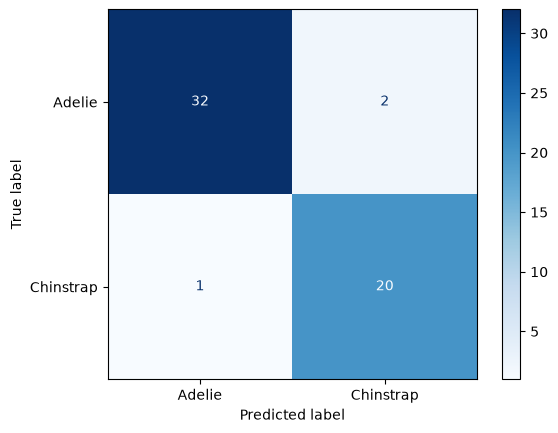

Test accuracy:  0.945
Train accuracy: 1.0


In [6]:
y_pred = classifier.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Adelie', 'Chinstrap']).plot(cmap='Blues')
plt.show()

print('Test accuracy: ', round(accuracy_score(y_test, y_pred), 3))
print('Train accuracy:', round(accuracy_score(y_train, classifier.predict(X_train_s)), 3))

## 6. Draw the decision boundary

We ask the model to classify every point on a grid and colour each cell by its answer. The boundary is a blend of many staircases, so it looks finer and steadier than a single tree's.

C:\jtmp\ipykernel_37912\278602332.py:10: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')


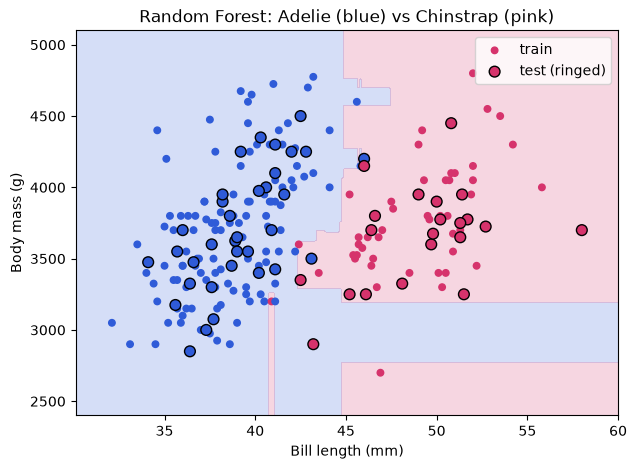

In [7]:
# a grid over the real units (mm and grams), scaled the same way as the training data
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

colors = ['#2f5bd8', '#d6336c']
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.2, levels=[-0.5, 0.5, 1.5], colors=colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=[colors[v] for v in y_train], s=22, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')
plt.xlabel('Bill length (mm)')
plt.ylabel('Body mass (g)')
plt.title('Random Forest: Adelie (blue) vs Chinstrap (pink)')
plt.legend()
plt.show()

## Try it yourself

- Try `n_estimators=1`, `10` and `100`. How much does the test accuracy change?
- Print `classifier.feature_importances_` to see which feature the forest relied on more.

## See it: the decision boundary

Each coloured area is where the model answers "Adelie" (blue) or "Chinstrap" (raspberry). **Notice how** the boundary is made of many small rectangles (each tree cuts straight across one feature), blended into a finer shape than one tree gives. The left panel shows the penguins the model learned from (filled dots). The right panel shows the penguins it has never seen (ringed dots): a ring sitting inside the wrong colour is a mistake. The accuracy is in each title.

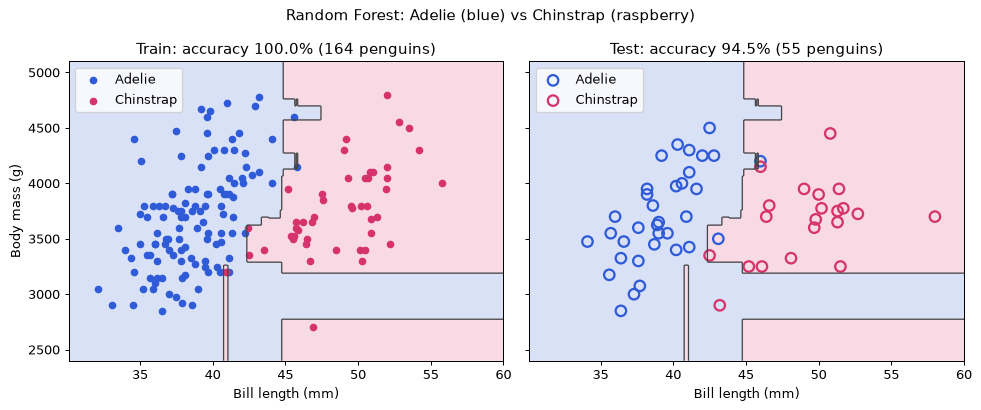

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
colors = [BLUE, PINK]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, Xp, yp, Xs in [(axes[0], 'Train', X_train, y_train, X_train_s),
                             (axes[1], 'Test', X_test, y_test, X_test_s)]:
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5], colors=colors)
    ax.contour(xx, yy, zz, levels=[0.5], colors='#444444', linewidths=1)
    acc = (classifier.predict(Xs) == yp).mean()
    for cls, label in [(0, 'Adelie'), (1, 'Chinstrap')]:
        pts = Xp[yp == cls]
        if name == 'Train':
            ax.scatter(pts[:, 0], pts[:, 1], color=colors[cls], s=26, label=label)
        else:
            ax.scatter(pts[:, 0], pts[:, 1], facecolors='none', edgecolors=colors[cls], s=70, linewidths=1.8, label=label)
    ax.set_title(f'{name}: accuracy {acc:.1%} ({len(Xp)} penguins)')
    ax.set_xlabel('Bill length (mm)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Body mass (g)')
fig.suptitle('Random Forest: Adelie (blue) vs Chinstrap (raspberry)')
fig.tight_layout()
plt.show()
